Graph loaded successfully with 242 nodes and 8317 edges.
Network Average Clustering Coefficient: 0.5255

Running targeted and random vaccination simulations (Immunizing top 35 nodes)...

--- Targeted vs. Random Vaccination Evaluation Table ---
                              Method  Avg_Final_Outbreak_Size
           Random Removal (Baseline)               207.000000
                     Standard Degree               206.966667
             Raw Cumulative Duration               207.000000
Modified Measure (Bridge + Temporal)               200.133333


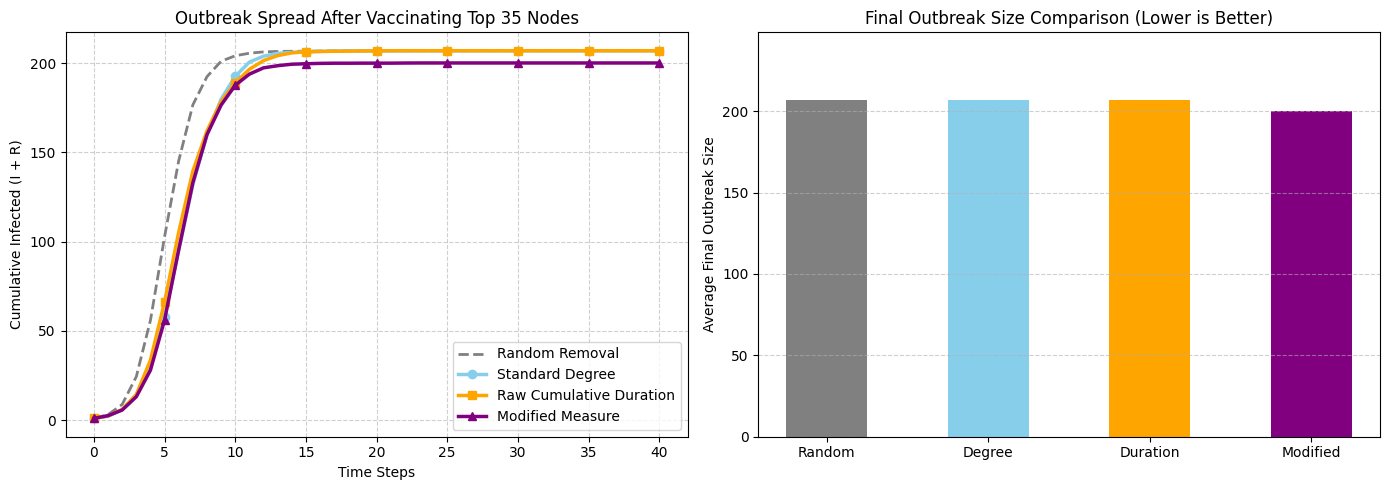

In [ ]:
import networkx as nx
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


def load_temporal_network(file_path='primaryschool.csv'):
    df = pd.read_csv(file_path, header=None, sep=',', names=['time', 'u', 'v', 'u_class', 'v_class'])
    return df

df = load_temporal_network('primaryschool.csv')

G_static = nx.Graph()
for _, row in df.iterrows():
    u, v = row['u'], row['v']
    if G_static.has_edge(u, v):
        G_static[u][v]['weight'] += 1
    else:
        G_static.add_edge(u, v, weight=1)

print(f"Graph loaded successfully with {G_static.number_of_nodes()} nodes and {G_static.number_of_edges()} edges.")


clustering_coeff = nx.clustering(G_static)
betweenness_cent = nx.betweenness_centrality(G_static)
print(f"Network Average Clustering Coefficient: {np.mean(list(clustering_coeff.values())):.4f}")


standard_degree = dict(G_static.degree())

raw_duration_centrality = dict(G_static.degree(weight='weight'))


modified_centrality = {}
for node in G_static.nodes():
    neighbors = list(G_static.neighbors(node))
    temporal_score = 0
    for nbr in neighbors:
        total_duration = G_static[node][nbr]['weight']
        edge_times = df[((df['u'] == node) & (df['v'] == nbr)) | ((df['u'] == nbr) & (df['v'] == node))]['time'].values
        if len(edge_times) > 1:
            inter_contact_times = np.diff(np.sort(edge_times))
            burstiness_factor = np.std(inter_contact_times) / (np.mean(inter_contact_times) + 1e-5)
        else:
            burstiness_factor = 0.0

        temporal_score += total_duration * (1.0 + burstiness_factor)


    bridge_weight = betweenness_cent.get(node, 0.0) * 1000.0
    modified_centrality[node] = temporal_score * (1.0 + bridge_weight)




def run_sir_with_vaccination(G, vaccinated_nodes, beta=0.03, gamma=0.05, steps=40):

    G_active = G.copy()
    G_active.remove_nodes_from(vaccinated_nodes)

    if G_active.number_of_nodes() == 0:
        return [0] * (steps + 1)

    available_nodes = list(G_active.nodes())
    initial_node = np.random.choice(available_nodes)

    status = {node: 'S' for node in G_active.nodes()}
    status[initial_node] = 'I'
    timeline = [sum(1 for s in status.values() if s in ['I', 'R'])]

    for _ in range(steps):
        newly_infected = []
        for node in list(status.keys()):
            if status[node] == 'I':
                for nbr in G_active.neighbors(node):
                    if status[nbr] == 'S' and np.random.rand() < beta:
                        newly_infected.append(nbr)
                if np.random.rand() < gamma:
                    status[node] = 'R'

        for nbr in newly_infected:
            status[nbr] = 'I'

        current_infected_count = sum(1 for s in status.values() if s in ['I', 'R'])
        timeline.append(current_infected_count)

    return timeline

K_vaccinate = 35
top_degree_vaccine = sorted(G_static.nodes(), key=lambda n: standard_degree[n], reverse=True)[:K_vaccinate]
top_duration_vaccine = sorted(G_static.nodes(), key=lambda n: raw_duration_centrality[n], reverse=True)[:K_vaccinate]
top_modified_vaccine = sorted(G_static.nodes(), key=lambda n: modified_centrality[n], reverse=True)[:K_vaccinate]
random_vaccine = list(np.random.choice(list(G_static.nodes()), size=K_vaccinate, replace=False))

print(f"\nRunning targeted and random vaccination simulations (Immunizing top {K_vaccinate} nodes)...")

def evaluate_vaccination_strategy(vaccinated_node_list, trials=30):
    all_timelines = []
    final_sizes = []
    for _ in range(trials):
        timeline = run_sir_with_vaccination(G_static, vaccinated_node_list)
        all_timelines.append(timeline)
        final_sizes.append(timeline[-1])
    return np.mean(all_timelines, axis=0), np.mean(final_sizes)

rand_timeline, rand_final = evaluate_vaccination_strategy(random_vaccine)
deg_timeline, deg_final = evaluate_vaccination_strategy(top_degree_vaccine)
dur_timeline, dur_final = evaluate_vaccination_strategy(top_duration_vaccine)
mod_timeline, mod_final = evaluate_vaccination_strategy(top_modified_vaccine)


eval_summary = pd.DataFrame([
    {'Method': 'Random Removal (Baseline)', 'Avg_Final_Outbreak_Size': rand_final},
    {'Method': 'Standard Degree', 'Avg_Final_Outbreak_Size': deg_final},
    {'Method': 'Raw Cumulative Duration', 'Avg_Final_Outbreak_Size': dur_final},
    {'Method': 'Modified Measure (Bridge + Temporal)', 'Avg_Final_Outbreak_Size': mod_final}
])
print("\n--- Targeted vs. Random Vaccination Evaluation Table ---")
print(eval_summary.to_string(index=False))




fig, axes = plt.subplots(1, 2, figsize=(14, 5))


axes[0].plot(rand_timeline, label='Random Removal', color='gray', linestyle='--', linewidth=2)
axes[0].plot(deg_timeline, label='Standard Degree', color='skyblue', linewidth=2.5, marker='o', markevery=5)
axes[0].plot(dur_timeline, label='Raw Cumulative Duration', color='orange', linewidth=2.5, marker='s', markevery=5)
axes[0].plot(mod_timeline, label='Modified Measure', color='purple', linewidth=2.5, marker='^', markevery=5)
axes[0].set_title(f'Outbreak Spread After Vaccinating Top {K_vaccinate} Nodes')
axes[0].set_xlabel('Time Steps')
axes[0].set_ylabel('Cumulative Infected (I + R)')
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend()


methods = ['Random', 'Degree', 'Duration', 'Modified']
avg_spreads = [rand_final, deg_final, dur_final, mod_final]
colors = ['gray', 'skyblue', 'orange', 'purple']

axes[1].bar(methods, avg_spreads, color=colors, width=0.5)
axes[1].set_title('Final Outbreak Size Comparison (Lower is Better)')
axes[1].set_ylabel('Average Final Outbreak Size')
axes[1].set_ylim(0, max(avg_spreads) * 1.2)
axes[1].grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('vaccination_strategy_evaluation.png', dpi=300)
plt.show()